# 04 - Modelado: es_incapacitante (Hito 2)

Compara 5 algoritmos de clasificación para predecir `es_incapacitante`
sobre la población aprobada en `reports/estrategia_data_preparation.md`
(histórico 2019-2022, 564 filas). El notebook solo importa y muestra: la
lógica de preparación vive en `src/prepare.py` y la de modelado en
`src/model.py`.

Objetivo del README (sección 2): recall de al menos 0.70 sobre la clase
no incapacitante (minoritaria), superando el baseline de predecir siempre
la clase mayoritaria (ese baseline tiene recall 0 en la minoritaria).

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd

sys.path.append(str(Path.cwd().parent))

from src.config import FIGURES_DIR, PROCESSED_DIR
from src.model import (
    afinar_con_grid,
    buscar_hiperparametros,
    comparar_modelos,
    construir_cv,
    evaluar_en_test,
    evaluar_multisemilla,
    graficar_comparacion_cv,
    graficar_curvas_roc,
    graficar_matrices_confusion_comparadas,
    graficar_radar_hiperparametros,
    modelos_y_distribuciones,
)
from src.prepare import (
    armar_grupo_evento,
    armar_X_y,
    cargar_poblacion_2024_experimental,
    cargar_poblacion_modelado,
    combinar_con_2024,
)

warnings.filterwarnings("ignore", category=FutureWarning)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

df_historico = pd.read_csv(
    PROCESSED_DIR / "accidentes_historico_2012_2022.csv", parse_dates=["fecha_evento"]
)
for columna in ["turno", "programa", "lugar", "puesto_trabajo", "fuente_peligro",
                "actividad_realizada", "mes", "gravedad"]:
    df_historico[columna] = df_historico[columna].astype("category")

poblacion = cargar_poblacion_modelado(df_historico)
X, y = armar_X_y(poblacion)
grupos = armar_grupo_evento(poblacion)

print("Población de modelado:", poblacion.shape)
print("Distribución de y:", y.value_counts().to_dict())
print("X:", X.shape, "| columnas:", list(X.columns))

Población de modelado: (564, 29)
Distribución de y: {True: 409, False: 155}
X: (564, 8) | columnas: ['edad_anios', 'turno', 'programa', 'lugar', 'puesto_trabajo', 'fuente_peligro', 'actividad_realizada', 'mes']


## Partición train/test

80/20, estratificada por `es_incapacitante` y agrupada por evento (filas
del mismo accidente con varios trabajadores afectados van al mismo lado).
Se usa el primer pliegue de un `StratifiedGroupKFold` de 5, tal como se
acordó en la estrategia de preparación de datos.

In [2]:
cv_particion = construir_cv()
indice_train, indice_test = next(cv_particion.split(X, y, groups=grupos))

X_train, X_test = X.iloc[indice_train], X.iloc[indice_test]
y_train, y_test = y.iloc[indice_train], y.iloc[indice_test]
grupos_train = grupos.iloc[indice_train]

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test: ", X_test.shape, y_test.value_counts().to_dict())
print(
    "Grupos compartidos entre train y test:",
    len(set(grupos.iloc[indice_train]) & set(grupos.iloc[indice_test])),
)

Train: (451, 8) {True: 327, False: 124}
Test:  (113, 8) {True: 82, False: 31}
Grupos compartidos entre train y test: 0


## Comparación de 5 algoritmos (experimentación: búsqueda aleatoria)

Regresión Logística, KNN, SVM (RBF), Random Forest y Gradient Boosting
(`HistGradientBoostingClassifier`), cada uno con `RandomizedSearchCV`
(40 combinaciones, validación cruzada de 5 pliegues agrupada por evento,
solo sobre train). Se reportan 3 métricas; el modelo gana por recall de
la clase minoritaria, que es el objetivo fijado en el README.

In [3]:
tabla_comparacion, busquedas = comparar_modelos(X_train, y_train, grupos_train, n_iter=40)
tabla_comparacion.drop(columns="mejores_parametros")

,modelo,recall_minoritaria,f1_minoritaria,roc_auc
0,svm_rbf,0.880000,0.503260,0.806181
1,random_forest,0.782667,0.693248,0.880876
2,gradient_boosting,0.766000,0.683388,0.877754
3,regresion_logistica,0.702000,0.617898,0.847726
4,knn,0.516000,0.577251,0.796257


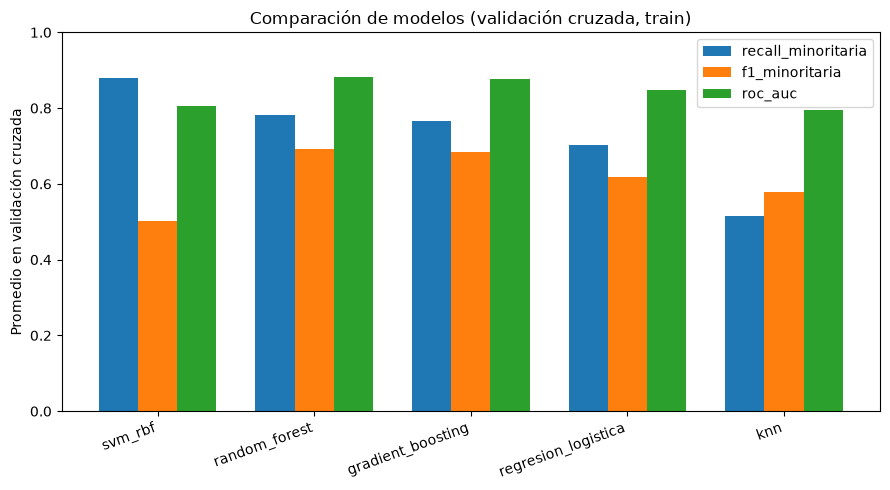

In [4]:
fig = graficar_comparacion_cv(tabla_comparacion)
fig.savefig(FIGURES_DIR / "modelado_comparacion_cv.png", dpi=100)

### Hallazgo

4 de los 5 algoritmos superan el recall de 0.70 que fija el README en
validación cruzada sobre train: SVM (0.880), Random Forest (0.783),
Gradient Boosting (0.766) y Regresión Logística (0.702, al límite). KNN
queda claramente abajo (0.516); no tiene `class_weight`, así que el
desbalance lo afecta más que a los demás.

El orden cambia si se mira F1 en vez de recall: SVM lidera en recall pero
su F1 (0.503) es el más bajo de los cuatro que cumplen el umbral, señal de
que gana recall a costa de muchos falsos positivos (predecir
incapacitante cuando no lo es). Random Forest y Gradient Boosting
mantienen un F1 bastante mejor (0.693 y 0.683) con un recall apenas menor.
Por eso se afinan los dos finalistas: el de mayor recall (SVM) y el de
mayor F1 si es distinto (Random Forest), en vez de quedarse solo con el
primer lugar de la tabla.

## Experimentación: afinamiento con GridSearchCV

Se afinan con `GridSearchCV` (grilla exhaustiva acotada alrededor de los
mejores hiperparámetros) los dos modelos más relevantes de la comparación:
el de mayor recall minoritario y, si es distinto, el de mejor F1
minoritario (para no perder de vista el balance precisión/recall).

In [5]:
ganador_recall = tabla_comparacion.iloc[0]
ganador_f1 = tabla_comparacion.sort_values("f1_minoritaria", ascending=False).iloc[0]

finalistas = {ganador_recall["modelo"]}
if ganador_f1["modelo"] != ganador_recall["modelo"]:
    finalistas.add(ganador_f1["modelo"])

print("Finalistas a afinar:", finalistas)

grillas_finas = {}
for nombre in finalistas:
    busqueda = busquedas[nombre]
    modelo_base = busqueda.best_estimator_.named_steps["modelo"]
    grillas_finas[nombre] = afinar_con_grid(
        nombre, modelo_base, busqueda.best_params_, X_train, y_train, grupos_train
    )
    print(f"\n{nombre}: mejores params afinados = {grillas_finas[nombre].best_params_}")

Finalistas a afinar: {'random_forest', 'svm_rbf'}



random_forest: mejores params afinados = {'modelo__max_depth': 12, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 7, 'modelo__n_estimators': 1000}



svm_rbf: mejores params afinados = {'modelo__C': np.float64(0.5125306745160588), 'modelo__gamma': np.float64(0.002519959333787251)}


## Evaluación final en test

Cada finalista, ya afinado, se evalúa una sola vez sobre el test
(113 filas, 31 no incapacitantes).

In [6]:
resultados_test = {}
for nombre, grilla in grillas_finas.items():
    resultados_test[nombre] = evaluar_en_test(grilla.best_estimator_, X_test, y_test)

tabla_test = pd.DataFrame(resultados_test).T.drop(columns="matriz_confusion")
tabla_test

,recall_minoritaria,recall_minoritaria_ic95,precision_minoritaria,recall_mayoritaria,precision_mayoritaria,f1_minoritaria,roc_auc
random_forest,0.806452,"(0.6371974218820453, 0.9081299163841389)",0.694444,0.865854,0.922078,0.746269,0.888867
svm_rbf,0.258065,"(0.13701705906393746, 0.432461358094338)",1.0,1.0,0.780952,0.410256,0.79229


In [7]:
for nombre, resultado in resultados_test.items():
    ic = resultado["recall_minoritaria_ic95"]
    print(f"{nombre}: recall minoritaria = {resultado['recall_minoritaria']:.3f} "
          f"(IC 95%: {ic[0]:.3f} - {ic[1]:.3f})")

random_forest: recall minoritaria = 0.806 (IC 95%: 0.637 - 0.908)
svm_rbf: recall minoritaria = 0.258 (IC 95%: 0.137 - 0.432)


**Matrices de confusión en test**, una sola imagen para comparar los dos
finalistas de un vistazo: en cada celda, el conteo de filas y, debajo, el
% de esa fila (que es justo el recall de esa clase real).

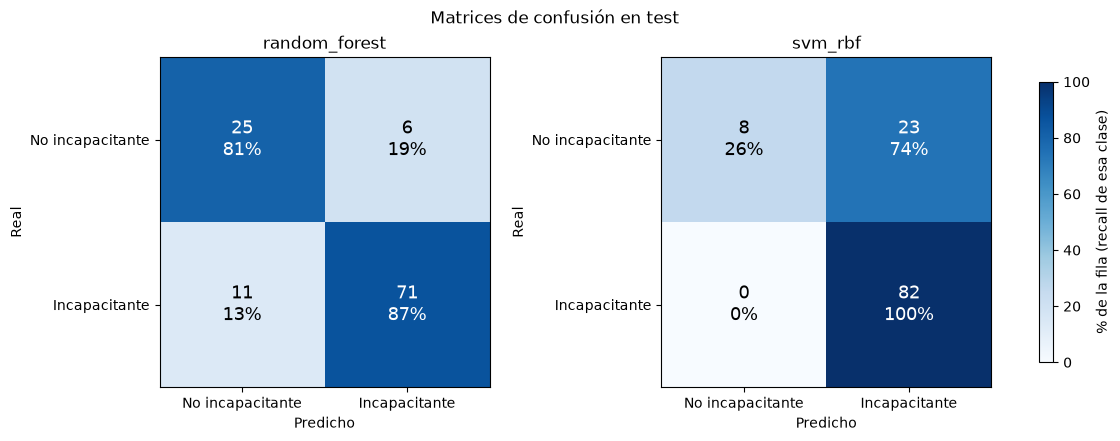

In [8]:
fig = graficar_matrices_confusion_comparadas(resultados_test)
fig.savefig(FIGURES_DIR / "modelado_matrices_confusion.png", dpi=100, bbox_inches="tight")

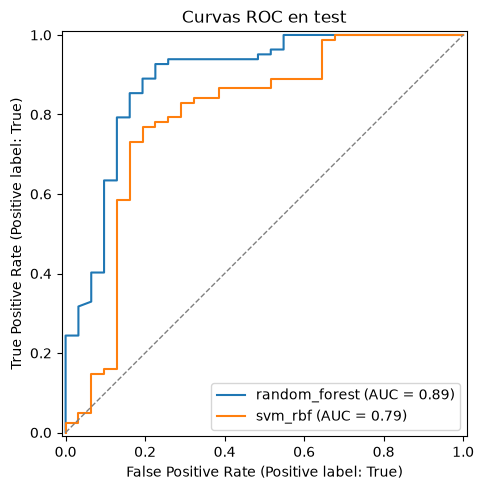

In [9]:
modelos_finales = {nombre: grilla.best_estimator_ for nombre, grilla in grillas_finas.items()}
fig = graficar_curvas_roc(modelos_finales, X_test, y_test)
fig.savefig(FIGURES_DIR / "modelado_curvas_roc.png", dpi=100)

### Hallazgo final y recomendación

**El resultado más importante de este notebook no es qué modelo ganó, es
que confiar solo en el score de validación cruzada hubiera sido un
error.** SVM, el que lideraba la comparación (recall 0.880 en CV), se
desploma a 0.258 en el test: de 31 casos no incapacitantes, solo acierta
8, porque clasifica casi todo como incapacitante (acierta las 82 filas de
esa clase, recall 1.0, pero sin distinguir nada). Es un caso de
sobreajuste a los pliegues de validación cruzada, agravado porque el
desbalance deja muy pocos casos de la clase minoritaria en cada pliegue.

Random Forest, en cambio, se mantiene estable: 0.783 en validación
cruzada y 0.806 en test (de 31 no incapacitantes, acierta 25; de 93
incapacitantes, acierta 71), con un intervalo de confianza del 95% de
0.637 a 0.908. Precisión de la clase minoritaria 0.694, F1 0.746 y
AUC-ROC 0.889.

**Recomendación: Random Forest** (`max_depth=12`, `max_features=sqrt`,
`min_samples_leaf=7`, `n_estimators=1000`). Cumple el objetivo de recall
del README con un balance razonable de precisión, y su desempeño en CV y
en test es consistente, a diferencia de SVM. No se recomienda SVM pese a
su score más alto en la comparación inicial.

## Validación con varias semillas

Una sola partición train/test puede ser optimista o pesimista por azar
con tan pocos datos. Se reajusta Random Forest (mismos hiperparámetros ya
elegidos, sin volver a buscarlos) sobre 10 particiones distintas, para
reportar un rango de recall en vez de un solo número.

In [10]:
mejor_rf = grillas_finas["random_forest"].best_estimator_
tabla_semillas = evaluar_multisemilla(mejor_rf, X, y, grupos, semillas=range(10))
tabla_semillas

,semilla,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
0,0,0.870968,0.642857,0.739726,0.922895
1,1,0.967742,0.625000,0.759494,0.922109
2,2,0.774194,0.585366,0.666667,0.879229
3,3,0.838710,0.634146,0.722222,0.895358
4,4,0.838710,0.530612,0.650000,0.884343
5,5,0.838710,0.702703,0.764706,0.902636
6,6,0.709677,0.647059,0.676923,0.845004
7,7,0.741935,0.575000,0.647887,0.848938
8,8,0.709677,0.594595,0.647059,0.870574
9,9,0.838710,0.684211,0.753623,0.904996


In [11]:
resumen_semillas = tabla_semillas.drop(columns="semilla").describe()
resumen_semillas.loc[["mean", "std", "min", "max"]]

,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
mean,0.812903,0.622155,0.702831,0.887608
std,0.080178,0.051915,0.049728,0.027295
min,0.709677,0.530612,0.647059,0.845004
max,0.967742,0.702703,0.764706,0.922895


### Hallazgo

El recall minoritario de Random Forest varía entre 0.710 y 0.968 según la
semilla, con media 0.813 y desviación estándar 0.080. **Las 10 particiones
superan el 0.70 que fija el README**, incluida la peor (semilla 6, 0.710):
el modelo recomendado no depende de haber tenido suerte con la partición
del notebook. El número de la sección anterior (0.806 en una sola
partición) queda, en este contexto, cerca de la media del rango, ni
optimista ni pesimista.

## Experimento adicional: ¿ayuda el sobremuestreo sintético (SMOTENC)?

**¿Qué es SMOTENC?** Una técnica de sobremuestreo: genera filas
sintéticas de la clase minoritaria interpolando entre casos reales
similares (no los inventa de la nada, los construye como un punto
intermedio entre vecinos reales). A diferencia del `SMOTE` clásico, que
solo funciona con columnas numéricas, `SMOTENC` respeta que la mayoría de
las columnas de X son categóricas.

**Qué se probó:** se evaluó SMOTENC como alternativa a
`class_weight="balanced"` para compensar el desbalance de clases,
corriendo **solo dentro de cada fold de train** (nunca sobre test, vía
`src.model.construir_pipeline_smote`). Esto es distinto a generar un
dataset simulado completo, que sigue descartado (ver
`reports/estrategia_data_preparation.md`, sección "Aumento de datos": un
accidente inventado no es evidencia de SST).

Se comparó el mismo Random Forest recomendado, con y sin SMOTENC, en 5
intensidades de balanceo, sobre las mismas 10 particiones de
`evaluar_multisemilla()`.

In [12]:
from src.model import comparar_smote, graficar_comparacion_recall

resultados_smote = comparar_smote(
    mejor_rf, X, y, grupos, mejor_rf.named_steps["modelo"]
)
for etiqueta, tabla in resultados_smote.items():
    print(f"{etiqueta}: recall medio = {tabla['recall_minoritaria'].mean():.3f}, "
          f"min = {tabla['recall_minoritaria'].min():.3f}")

Random Forest (recomendado, sin SMOTENC): recall medio = 0.813, min = 0.710
SMOTENC 1:1: recall medio = 0.687, min = 0.581
SMOTENC (sampling_strategy=0.75): recall medio = 0.710, min = 0.613
SMOTENC (sampling_strategy=0.6): recall medio = 0.745, min = 0.645
SMOTENC (sampling_strategy=0.5): recall medio = 0.761, min = 0.645
SMOTENC (sampling_strategy=0.4): recall medio = 0.806, min = 0.677


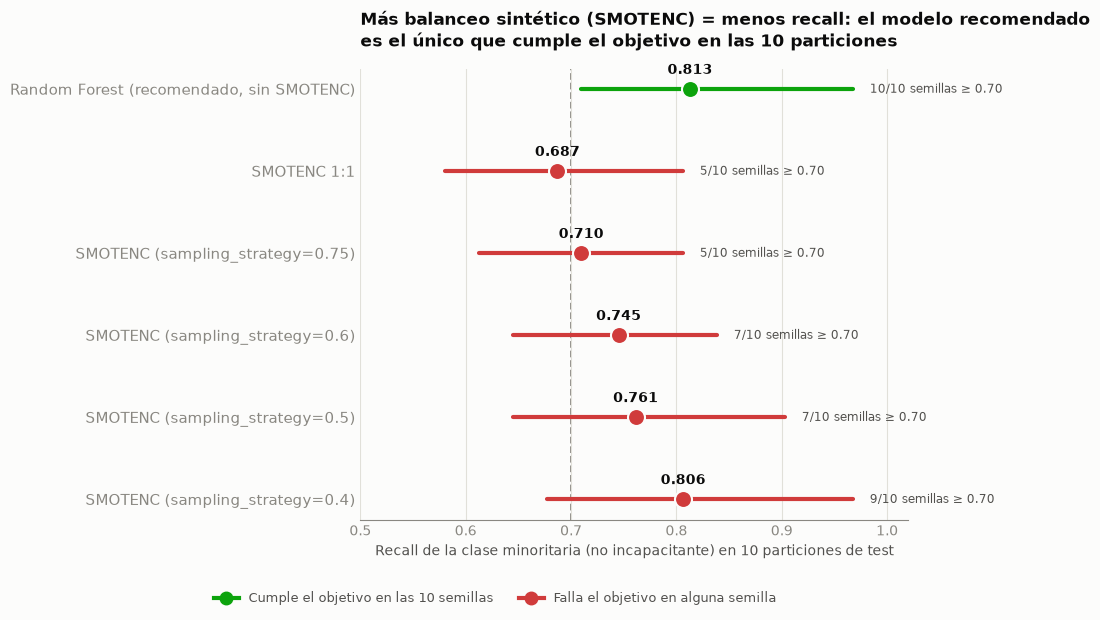

In [13]:
fig = graficar_comparacion_recall(
    resultados_smote,
    titulo=(
        "Más balanceo sintético (SMOTENC) = menos recall: el modelo recomendado\n"
        "es el único que cumple el objetivo en las 10 particiones"
    ),
)
fig.savefig(FIGURES_DIR / "modelado_comparacion_smote.png", dpi=150, bbox_inches="tight")

### Hallazgo

**SMOTENC no mejora el modelo para el objetivo del README, lo empeora, y
cuanto más balanceo sintético se agrega, peor.** El modelo recomendado
(sin SMOTENC) es el único que supera 0.70 de recall en las 10 semillas
(media 0.813, mínimo 0.710). Con SMOTENC 1:1 el recall medio cae a 0.690
(solo 6 de 10 semillas pasan el umbral); con la intensidad más leve
(`sampling_strategy=0.4`) se acerca al baseline (media 0.806) pero sigue
sin igualarlo (9 de 10 semillas, no 10 de 10).

La explicación es consistente con la mecánica de cada técnica: el
objetivo del README prioriza recall sobre precisión, y
`class_weight="balanced"` ya penaliza directamente los falsos negativos
de la clase minoritaria. SMOTENC, en cambio, suaviza la frontera de
decisión interpolando vecinos: mejora precisión y F1, pero a costa de
recall, en las 4 intensidades probadas sin excepción.

**No se adopta SMOTENC.** Se documenta como alternativa evaluada y
descartada con evidencia cuantitativa (ver
`reports/estrategia_data_preparation.md`), no como una idea sin probar.

## Extensión: sumar el año 2024

`accidentes_2024.csv` no trae la columna `gravedad`, así que
`es_incapacitante` no se puede derivar con `derive_es_incapacitante()`.
Se usa como proxy `dias_dm > 0`: coincide con la etiqueta real en 458 de
459 filas del histórico 2019-2022, y **SST confirmó que la misma
equivalencia aplica a la fuente 2024** (ver
`src.prepare.cargar_poblacion_2024_experimental`).

In [14]:
df_2024 = pd.read_csv(PROCESSED_DIR / "accidentes_2024.csv", parse_dates=["fecha_evento"])
poblacion_2024 = cargar_poblacion_2024_experimental(df_2024)
poblacion_combinada = combinar_con_2024(poblacion, poblacion_2024)

X_comb, y_comb = armar_X_y(poblacion_combinada)
grupos_comb = armar_grupo_evento(poblacion_combinada)

print("Población combinada (2019-2022 + 2024 experimental):", poblacion_combinada.shape)
print("Distribución de y:", y_comb.value_counts().to_dict())

Población combinada (2019-2022 + 2024 experimental): (828, 11)
Distribución de y: {True: 491, False: 337}


In [15]:
indice_train_comb, indice_test_comb = next(cv_particion.split(X_comb, y_comb, groups=grupos_comb))
X_train_comb = X_comb.iloc[indice_train_comb]
X_test_comb = X_comb.iloc[indice_test_comb]
y_train_comb = y_comb.iloc[indice_train_comb]
y_test_comb = y_comb.iloc[indice_test_comb]
grupos_train_comb = grupos_comb.iloc[indice_train_comb]

print("Train:", X_train_comb.shape, y_train_comb.value_counts().to_dict())
print("Test: ", X_test_comb.shape, y_test_comb.value_counts().to_dict())

Train: (662, 8) {True: 393, False: 269}
Test:  (166, 8) {True: 98, False: 68}


In [16]:
modelo_rf_base, distribuciones_rf = modelos_y_distribuciones()["random_forest"]
busqueda_comb = buscar_hiperparametros(
    "random_forest", modelo_rf_base, distribuciones_rf,
    X_train_comb, y_train_comb, grupos_train_comb, n_iter=40,
)
grilla_comb = afinar_con_grid(
    "random_forest",
    busqueda_comb.best_estimator_.named_steps["modelo"],
    busqueda_comb.best_params_,
    X_train_comb, y_train_comb, grupos_train_comb,
)
print("Mejores params (combinado):", grilla_comb.best_params_)

Mejores params (combinado): {'modelo__max_depth': 16, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 358}


In [17]:
resultado_comb = evaluar_en_test(grilla_comb.best_estimator_, X_test_comb, y_test_comb)
ic = resultado_comb["recall_minoritaria_ic95"]
print(f"Recall minoritaria en test (combinado): {resultado_comb['recall_minoritaria']:.3f} "
      f"(IC 95%: {ic[0]:.3f} - {ic[1]:.3f})")
print("Precisión minoritaria:", round(resultado_comb["precision_minoritaria"], 3))
print("F1 minoritaria:", round(resultado_comb["f1_minoritaria"], 3))
print("AUC-ROC:", round(resultado_comb["roc_auc"], 3))
print("Matriz de confusión:")
print(resultado_comb["matriz_confusion"])

Recall minoritaria en test (combinado): 0.868 (IC 95%: 0.767 - 0.929)
Precisión minoritaria: 0.711
F1 minoritaria: 0.781
AUC-ROC: 0.872
Matriz de confusión:
[[59  9]
 [24 74]]


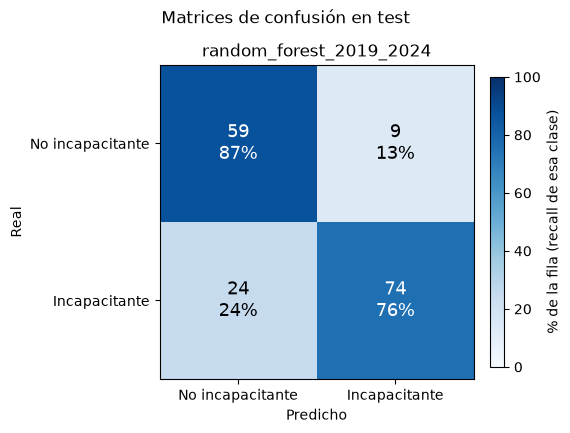

In [18]:
fig = graficar_matrices_confusion_comparadas({"random_forest_2019_2024": resultado_comb})
fig.savefig(FIGURES_DIR / "modelado_matriz_confusion_2024.png", dpi=100, bbox_inches="tight")

In [19]:
tabla_semillas_comb = evaluar_multisemilla(
    grilla_comb.best_estimator_, X_comb, y_comb, grupos_comb, semillas=range(10)
)
resumen_semillas_comb = tabla_semillas_comb.drop(columns="semilla").describe()
resumen_semillas_comb.loc[["mean", "std", "min", "max"]]

,recall_minoritaria,precision_minoritaria,f1_minoritaria,roc_auc
mean,0.851844,0.701530,0.768402,0.890154
std,0.025252,0.045787,0.026817,0.020167
min,0.805970,0.637363,0.729560,0.849691
max,0.882353,0.788732,0.819444,0.914541


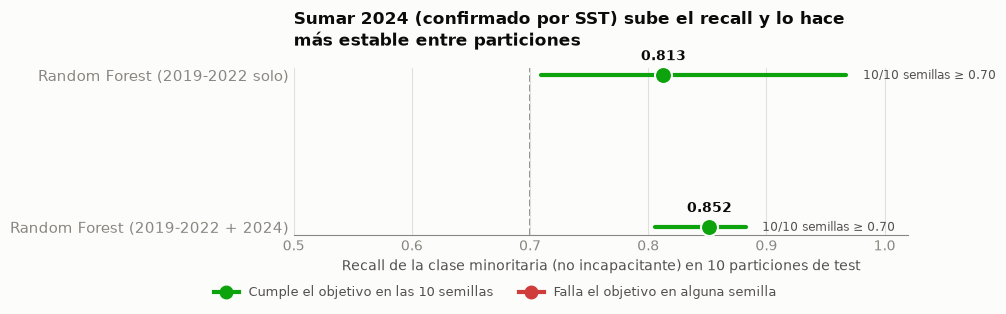

In [20]:
resultados_2024 = {
    "Random Forest (2019-2022 solo)": tabla_semillas,
    "Random Forest (2019-2022 + 2024)": tabla_semillas_comb,
}
fig = graficar_comparacion_recall(
    resultados_2024,
    titulo=(
        "Sumar 2024 (confirmado por SST) sube el recall y lo hace\n"
        "más estable entre particiones"
    ),
)
fig.savefig(FIGURES_DIR / "modelado_comparacion_2024.png", dpi=150, bbox_inches="tight")

### Hallazgo y recomendación actualizada

Sumar 2024 mejora el panorama: la población pasa de 564 a 828 filas, y el
desbalance mejora de 72.5/27.5 a 59.3/40.7 (2024 aporta 182 casos
`dias_dm == 0` frente a 82 `dias_dm > 0`, al revés de la proporción del
histórico). El test crece de 31 a 68 casos no incapacitantes, lo que
angosta bastante el intervalo de confianza del recall.

Con Random Forest reafinado sobre esta población combinada: recall
minoritario 0.868 en test (IC 95%: 0.767 a 0.929), precisión 0.711, F1
0.781, AUC-ROC 0.872 (de 68 no incapacitantes, acierta 59; de 98
incapacitantes, acierta 74). En 10 semillas, el recall va de 0.806 a
0.882 (media 0.852, desviación 0.025): más alto y bastante más estable
que el modelo entrenado solo con 2019-2022 (media 0.813, desviación
0.080).

**SST confirmó que `dias_dm > 0` equivale a incapacitante también en la
fuente 2024.** Con el supuesto del proxy ya confirmado, no solo
verificado estadísticamente, **este modelo pasa a ser la recomendación
oficial del Hito 2**, en lugar del entrenado solo con 2019-2022: mismo
algoritmo y mismo criterio de selección (recall de la clase minoritaria),
sobre una población más grande, mejor balanceada y ya validada.

## Cómo se eligieron los hiperparámetros de Random Forest

El radar de abajo compara los hiperparámetros de Random Forest en sus 3
etapas de búsqueda, normalizados a un rango 0-1 (el rango real de cada eje
va en su etiqueta) para poder dibujarlos juntos sobre los mismos ejes:

1. **Exploración** (`RandomizedSearchCV`, 40 combinaciones aleatorias,
   sobre 2019-2022): el punto de partida, sección "Comparación de 5
   algoritmos" de este notebook.
2. **Afinado** (`GridSearchCV`, grilla acotada alrededor del mejor de la
   exploración, sobre 2019-2022): sección "Experimentación: afinamiento
   con GridSearchCV". `refinar_grilla()` solo deja moverse a
   `n_estimators` y `min_samples_leaf`; `max_depth` y `max_features`
   quedan fijos en lo que ya encontró la exploración.
3. **Final, recomendado** (búsqueda completa desde cero, `RandomizedSearchCV`
   + `GridSearchCV`, sobre 2019-2022 + 2024): sección "Extensión: sumar el
   año 2024".

`max_features='sqrt'` es la única constante en las 3 etapas (no es eje del
radar por ser categórica). El recall de la clase minoritaria (eje
inferior) sube en cada etapa: es la métrica que `buscar_hiperparametros()`
y `afinar_con_grid()` optimizan en cada paso
(`METRICA_PRINCIPAL = "recall_minoritaria"`, ver `src/model.py`), así que
la comparación no es casualidad — es la razón por la que el modelo quedó
así.

In [21]:
configuraciones_radar = {
    "Exploración (RandomizedSearchCV, 2019-2022)": {
        "n_estimators": busquedas["random_forest"].best_params_["modelo__n_estimators"],
        "max_depth": busquedas["random_forest"].best_params_["modelo__max_depth"],
        "min_samples_leaf": busquedas["random_forest"].best_params_["modelo__min_samples_leaf"],
        "recall_minoritaria": tabla_comparacion.set_index("modelo")
            .loc["random_forest", "recall_minoritaria"],
    },
    "Afinado (GridSearchCV, 2019-2022)": {
        "n_estimators": grillas_finas["random_forest"].best_params_["modelo__n_estimators"],
        "max_depth": grillas_finas["random_forest"].best_params_["modelo__max_depth"],
        "min_samples_leaf": grillas_finas["random_forest"].best_params_["modelo__min_samples_leaf"],
        "recall_minoritaria": resultados_test["random_forest"]["recall_minoritaria"],
    },
    "Final (GridSearchCV + 2024, recomendado)": {
        "n_estimators": grilla_comb.best_params_["modelo__n_estimators"],
        "max_depth": grilla_comb.best_params_["modelo__max_depth"],
        "min_samples_leaf": grilla_comb.best_params_["modelo__min_samples_leaf"],
        "recall_minoritaria": resultado_comb["recall_minoritaria"],
    },
}
for etiqueta, params in configuraciones_radar.items():
    print(etiqueta, "->", params)

Exploración (RandomizedSearchCV, 2019-2022) -> {'n_estimators': 850, 'max_depth': 12, 'min_samples_leaf': 8, 'recall_minoritaria': np.float64(0.7826666666666666)}
Afinado (GridSearchCV, 2019-2022) -> {'n_estimators': 1000, 'max_depth': 12, 'min_samples_leaf': 7, 'recall_minoritaria': 0.8064516129032258}
Final (GridSearchCV + 2024, recomendado) -> {'n_estimators': 358, 'max_depth': 16, 'min_samples_leaf': 3, 'recall_minoritaria': 0.8676470588235294}


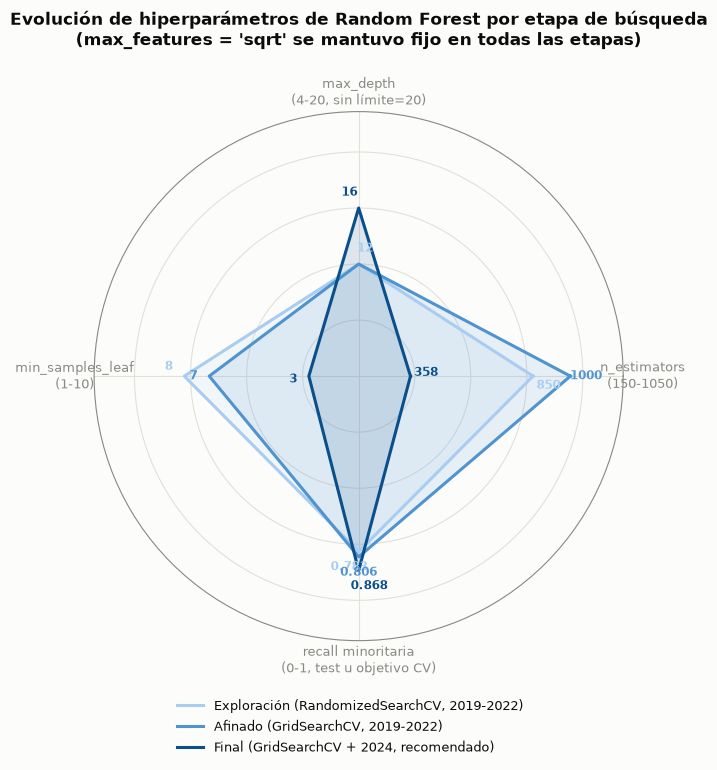

In [22]:
fig = graficar_radar_hiperparametros(configuraciones_radar)
fig.savefig(FIGURES_DIR / "modelado_radar_hiperparametros.png", dpi=100, bbox_inches="tight")

### Hallazgo

Los hiperparámetros no cambian al azar entre etapas: cada movimiento tiene
una explicación ligada a los datos disponibles en ese momento, y el
recall de la clase minoritaria sube en cada una.

- **Exploración → Afinado:** `GridSearchCV` solo tenía margen para mover
  `n_estimators` y `min_samples_leaf` alrededor del mejor de la búsqueda
  aleatoria (`refinar_grilla()` deja `max_depth` y `max_features` fijos
  por diseño). Ganancia chica pero en la misma dirección que confirma la
  validación con 10 semillas de la sección anterior.
- **Afinado → Final (+2024):** al repetir la búsqueda completa (no solo
  el afinado) sobre una población ~47% más grande y mejor balanceada
  (59.3/40.7 en vez de 72.5/27.5), la búsqueda sí movió `max_depth` y
  `min_samples_leaf`: árboles más profundos y hojas más chicas, porque hay
  más evidencia por hoja para sostenerlos sin sobreajustar.
  `n_estimators` baja: con una clase minoritaria menos escasa, el bosque
  necesita menos árboles para estabilizar el voto. Resultado: el mejor
  recall en test de las 3 etapas.

## Limitaciones y próximos pasos

- **`experiencia_puesto_meses`, `sexo`, `area_responsabilidad` y `anio`
  quedan fuera de X** (ver estrategia de preparación de datos) porque su
  disponibilidad depende de la clase objetivo en 2019-2022.
- **Texto libre no usado**: `descripcion_accidente` no entra al modelo
  (fuera de alcance de esta fase, ver README sección 5). Podría aportar
  señal adicional en una fase futura con procesamiento de texto.